In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization

In [2]:
DATASET_PATH = "/kaggle/input/datasets/ejlok1/toronto-emotional-speech-set-tess/TESS Toronto emotional speech set data"  
file_paths = []
labels = []

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.endswith('.wav'):
            path = os.path.join(root, file)
            folder_name = os.path.basename(root).lower()
            if 'angry' in folder_name: label = 'angry'
            elif 'disgust' in folder_name: label = 'disgust'
            elif 'fear' in folder_name: label = 'fear'
            elif 'happy' in folder_name or 'ps' in folder_name: label = 'happy'
            elif 'neutral' in folder_name: label = 'neutral'
            elif 'sad' in folder_name: label = 'sad'
            else: continue
            
            file_paths.append(path)
            labels.append(label)

df = pd.DataFrame({'path': file_paths, 'label': labels})
print(f"Total files loaded: {len(df)}")

Total files loaded: 2400


/tmp/ipykernel_58/3070045851.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='viridis')


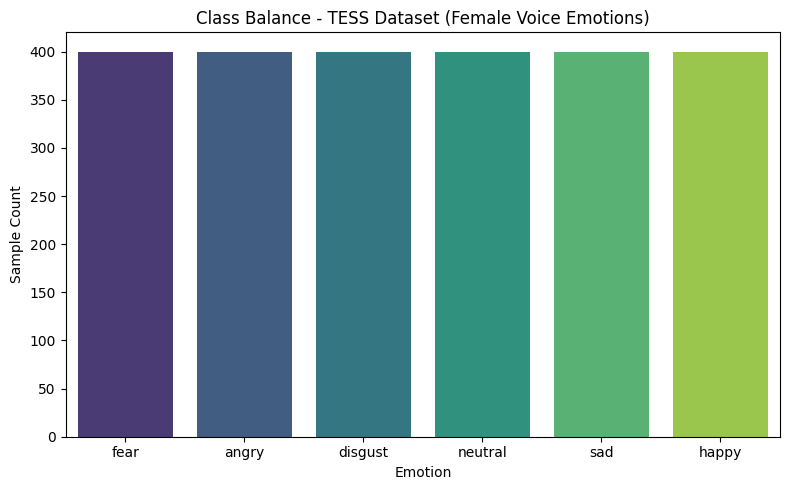

In [3]:
# Data Visualization & Class Balance Check
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label', palette='viridis')
plt.title("Class Balance - TESS Dataset (Female Voice Emotions)")
plt.xlabel("Emotion")
plt.ylabel("Sample Count")
plt.tight_layout()
plt.savefig("emotion_class_distribution.png")
plt.show()

In [4]:
#  Audio Feature Extraction 
def extract_features(file_path):
    # Load audio, resample to 22050 Hz, duration trimmed to 3s
    y, sr = librosa.load(file_path, duration=3, offset=0.5, sr=22050)
    # Extract 40 MFCC values averaged across time frames
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
    mfccs_scaled = np.mean(mfccs.T, axis=0)
    return mfccs_scaled

print("Extracting MFCC features from audio files...")
X = np.array([extract_features(p) for p in df['path']])
y = df['label'].values

Extracting MFCC features from audio files...


In [5]:
# Encode Labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
y_categorical = tf.keras.utils.to_categorical(y_encoded)

In [6]:
# Train-Test Split 
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, random_state=42, stratify=y_encoded
)

In [7]:
# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [8]:
# Save Scaler and Label Encoder for GUI inference
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
with open("label_encoder.pkl", "wb") as f:
    pickle.dump(label_encoder, f)

In [9]:
# Neural Network Architecture 
model = Sequential([
    Dense(256, activation='relu', input_shape=(40,)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(len(label_encoder.classes_), activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-09-05 11:13:54.160520: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [10]:
# Model Training
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7776 - loss: 0.6486 - val_accuracy: 0.9812 - val_loss: 0.4455
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9563 - loss: 0.1620 - val_accuracy: 0.9812 - val_loss: 0.1489
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9750 - loss: 0.0987 - val_accuracy: 0.9958 - val_loss: 0.0530
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9844 - loss: 0.0655 - val_accuracy: 0.9979 - val_loss: 0.0226
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9875 - loss: 0.0537 - val_accuracy: 0.9979 - val_loss: 0.0158
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9885 - loss: 0.0467 - val_accuracy: 1.0000 - val_loss: 0.0060
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9932 - loss: 0.0301 - val_accuracy: 1.0000 - val_loss: 0.0045
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9953 - loss: 0.0258 - val_accuracy: 1.0000 - val_loss:

In [ ]:
# 5. Save Trained Model
model.save("emotion_model.h5")


Model, Scaler, and Label Encoder saved successfully.


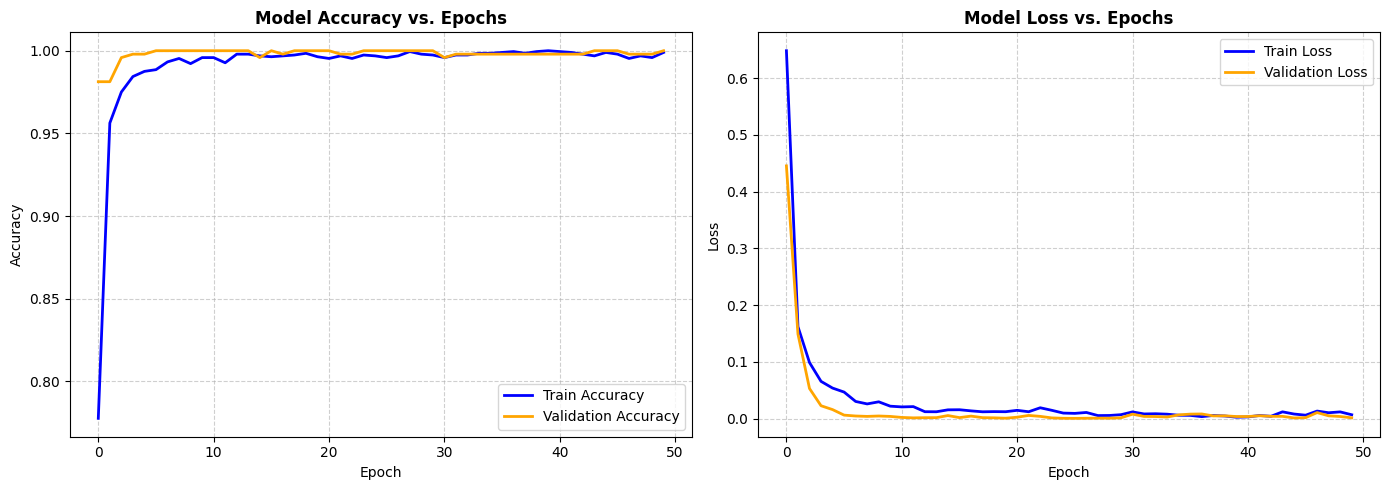

In [12]:
#  Save Model Loss & Accuracy Graphs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Plot
ax1.plot(history.history['accuracy'], label='Train Accuracy', color='blue', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
ax1.set_title('Model Accuracy vs. Epochs', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.6)

# Loss Plot
ax2.plot(history.history['loss'], label='Train Loss', color='blue', linewidth=2)
ax2.plot(history.history['val_loss'], label='Validation Loss', color='orange', linewidth=2)
ax2.set_title('Model Loss vs. Epochs', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig("model_training_performance.png")
plt.show()